In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("C:/Users/Santhoshkumar S/Downloads/flights.csv/flights.csv")
df.head()

,id,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,...,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,name
0,0,2013,1,1,517.0,515,2.0,830.0,819,11.0,...,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.
1,1,2013,1,1,533.0,529,4.0,850.0,830,20.0,...,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00,United Air Lines Inc.
2,2,2013,1,1,542.0,540,2.0,923.0,850,33.0,...,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00,American Airlines Inc.
3,3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,...,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00,JetBlue Airways
4,4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,...,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00,Delta Air Lines Inc.


In [3]:
print("Shape:", df.shape)
print("\nColumn Names:")
print(df.columns)
print("\nData Types:")
print(df.dtypes)
df.info()
print("\nMissing Values:")
print(df.isnull().sum())

Shape: (336776, 21)

Column Names:
Index(['id', 'year', 'month', 'day', 'dep_time', 'sched_dep_time', 'dep_delay',
       'arr_time', 'sched_arr_time', 'arr_delay', 'carrier', 'flight',
       'tailnum', 'origin', 'dest', 'air_time', 'distance', 'hour', 'minute',
       'time_hour', 'name'],
      dtype='str')

Data Types:
id                  int64
year                int64
month               int64
day                 int64
dep_time          float64
sched_dep_time      int64
dep_delay         float64
arr_time          float64
sched_arr_time      int64
arr_delay         float64
carrier               str
flight              int64
tailnum               str
origin                str
dest                  str
air_time          float64
distance            int64
hour                int64
minute              int64
time_hour             str
name                  str
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 336776 entries, 0 to 336775
Data columns (total 21 columns):
 #   Column    

In [4]:
num_cols = df.select_dtypes(include=np.number).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
cat_cols = df.select_dtypes(include='object').columns
for col in cat_cols:
    df[col] = df[col].fillna("Unknown")
print(df.isnull().sum())

C:\Users\Santhoshkumar S\AppData\Local\Temp\ipykernel_19432\2815958681.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns


id                0
year              0
month             0
day               0
dep_time          0
sched_dep_time    0
dep_delay         0
arr_time          0
sched_arr_time    0
arr_delay         0
carrier           0
flight            0
tailnum           0
origin            0
dest              0
air_time          0
distance          0
hour              0
minute            0
time_hour         0
name              0
dtype: int64


In [5]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['carrier_encoded'] = le.fit_transform(df['carrier'])
df['origin_encoded'] = le.fit_transform(df['origin'])
df['dest_encoded'] = le.fit_transform(df['dest'])

print(df[['carrier', 'carrier_encoded',
          'origin', 'origin_encoded',
          'dest', 'dest_encoded']].head())

  carrier  carrier_encoded origin  origin_encoded dest  dest_encoded
0      UA               11    EWR               0  IAH            43
1      UA               11    LGA               2  IAH            43
2      AA                1    JFK               1  MIA            58
3      B6                3    JFK               1  BQN            12
4      DL                4    LGA               2  ATL             4


In [6]:
# Carrier frequency
print("Carrier Frequency:")
print(df['carrier'].value_counts())

# Origin frequency
print("\nOrigin Frequency:")
print(df['origin'].value_counts())

# Destination frequency
print("\nDestination Frequency:")
print(df['dest'].value_counts())

Carrier Frequency:
carrier
UA    58665
B6    54635
EV    54173
DL    48110
AA    32729
MQ    26397
US    20536
9E    18460
WN    12275
VX     5162
FL     3260
AS      714
F9      685
YV      601
HA      342
OO       32
Name: count, dtype: int64

Origin Frequency:
origin
EWR    120835
JFK    111279
LGA    104662
Name: count, dtype: int64

Destination Frequency:
dest
ORD    17283
ATL    17215
LAX    16174
BOS    15508
MCO    14082
       ...  
MTJ       15
SBN       10
ANC        8
LEX        1
LGA        1
Name: count, Length: 105, dtype: int64


In [7]:
# Carrier percentage
print("Carrier Percentage:")
print(df['carrier'].value_counts(normalize=True) * 100)

# Origin percentage
print("\nOrigin Percentage:")
print(df['origin'].value_counts(normalize=True) * 100)

# Destination percentage
print("\nDestination Percentage:")
print(df['dest'].value_counts(normalize=True) * 100)

Carrier Percentage:
carrier
UA    17.419590
B6    16.222949
EV    16.085766
DL    14.285460
AA     9.718329
MQ     7.838148
US     6.097822
9E     5.481388
WN     3.644856
VX     1.532770
FL     0.968002
AS     0.212010
F9     0.203399
YV     0.178457
HA     0.101551
OO     0.009502
Name: proportion, dtype: float64

Origin Percentage:
origin
EWR    35.879932
JFK    33.042438
LGA    31.077630
Name: proportion, dtype: float64

Destination Percentage:
dest
ORD    5.131898
ATL    5.111706
LAX    4.802599
BOS    4.604841
MCO    4.181414
         ...   
MTJ    0.004454
SBN    0.002969
ANC    0.002375
LEX    0.000297
LGA    0.000297
Name: proportion, Length: 105, dtype: float64


In [8]:
# Carrier percentage
print("Carrier Percentage:")
print(df['carrier'].value_counts(normalize=True) * 100)

# Origin percentage
print("\nOrigin Percentage:")
print(df['origin'].value_counts(normalize=True) * 100)

# Destination percentage
print("\nDestination Percentage:")
print(df['dest'].value_counts(normalize=True) * 100)

Carrier Percentage:
carrier
UA    17.419590
B6    16.222949
EV    16.085766
DL    14.285460
AA     9.718329
MQ     7.838148
US     6.097822
9E     5.481388
WN     3.644856
VX     1.532770
FL     0.968002
AS     0.212010
F9     0.203399
YV     0.178457
HA     0.101551
OO     0.009502
Name: proportion, dtype: float64

Origin Percentage:
origin
EWR    35.879932
JFK    33.042438
LGA    31.077630
Name: proportion, dtype: float64

Destination Percentage:
dest
ORD    5.131898
ATL    5.111706
LAX    4.802599
BOS    4.604841
MCO    4.181414
         ...   
MTJ    0.004454
SBN    0.002969
ANC    0.002375
LEX    0.000297
LGA    0.000297
Name: proportion, Length: 105, dtype: float64


In [9]:
print("Most Common Carrier:")
print(df['carrier'].mode()[0])

print("\nMost Common Origin:")
print(df['origin'].mode()[0])

print("\nMost Common Destination:")
print(df['dest'].mode()[0])

Most Common Carrier:
UA

Most Common Origin:
EWR

Most Common Destination:
ORD


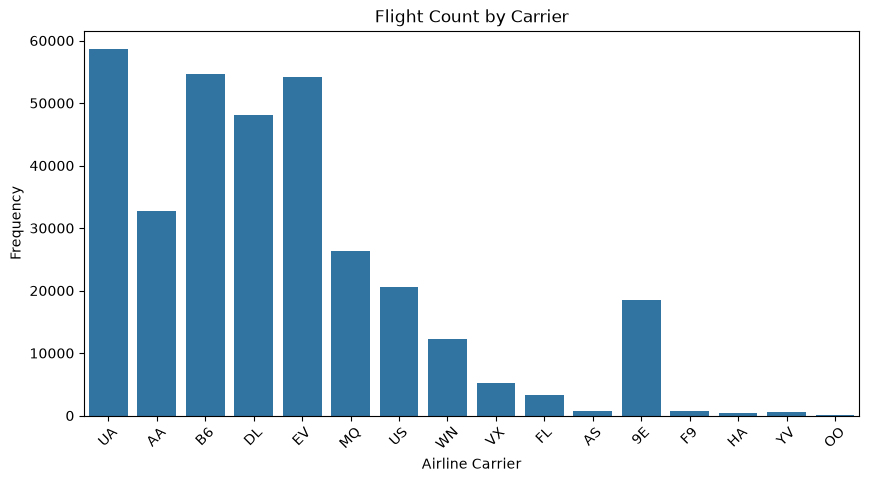

In [10]:
plt.figure(figsize=(10,5))

sns.countplot(data=df, x='carrier')

plt.title("Flight Count by Carrier")
plt.xlabel("Airline Carrier")
plt.ylabel("Frequency")
plt.xticks(rotation=45)

plt.show()

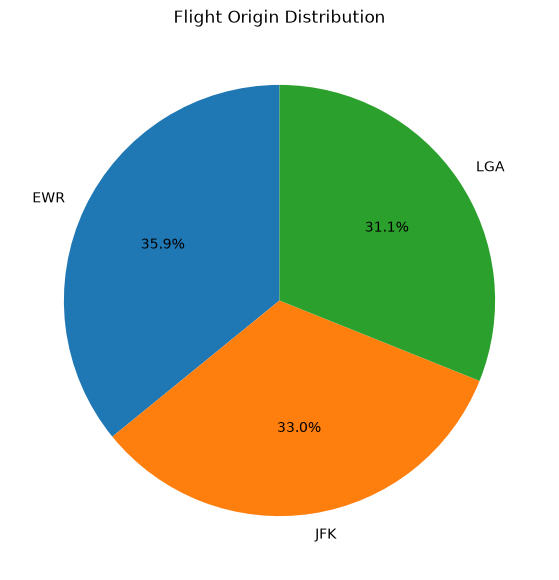

In [11]:
plt.figure(figsize=(7,7))

df['origin'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Flight Origin Distribution")
plt.ylabel("")

plt.show()

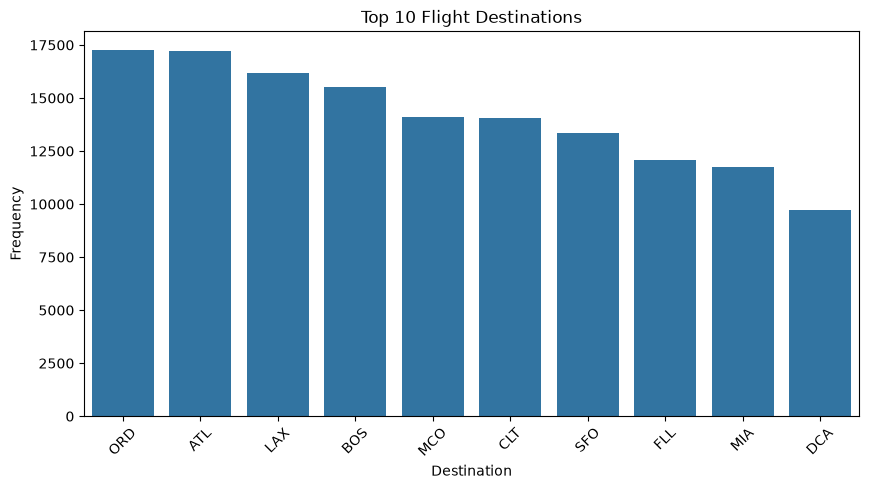

In [12]:
plt.figure(figsize=(10,5))

freq = df['dest'].value_counts().head(10)

sns.barplot(x=freq.index, y=freq.values)

plt.title("Top 10 Flight Destinations")
plt.xlabel("Destination")
plt.ylabel("Frequency")
plt.xticks(rotation=45)

plt.show()

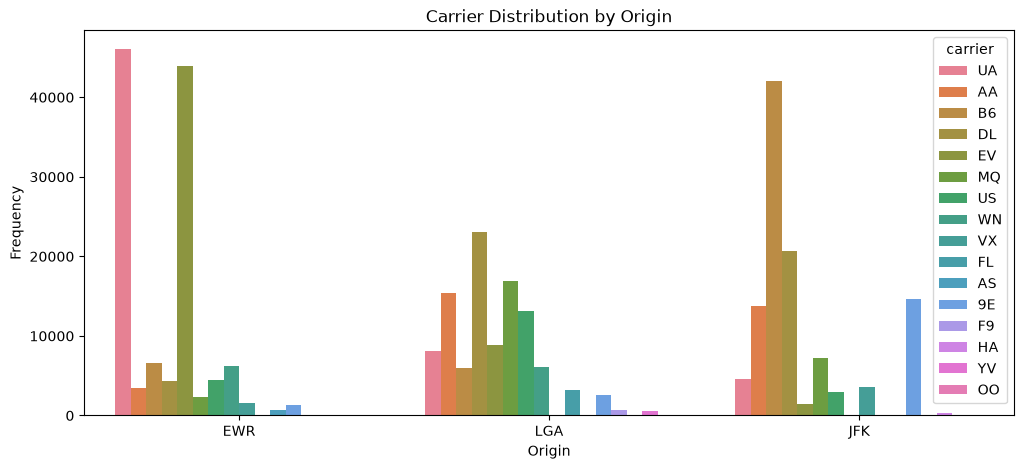

In [13]:
plt.figure(figsize=(12,5))

sns.countplot(data=df, x='origin', hue='carrier')

plt.title("Carrier Distribution by Origin")
plt.xlabel("Origin")
plt.ylabel("Frequency")

plt.show()

In [14]:
print("TOTAL FLIGHTS:", len(df))

print("\nTotal Airlines:", df['carrier'].nunique())

print("\nTotal Origins:", df['origin'].nunique())

print("\nTotal Destinations:", df['dest'].nunique())

print("\nMost Common Airline:", df['carrier'].mode()[0])

print("\nMost Common Origin:", df['origin'].mode()[0])

print("\nMost Common Destination:", df['dest'].mode()[0])

TOTAL FLIGHTS: 336776

Total Airlines: 16

Total Origins: 3

Total Destinations: 105

Most Common Airline: UA

Most Common Origin: EWR

Most Common Destination: ORD
